<a href="https://colab.research.google.com/github/Marco-5-0-5/ISS_project/blob/main/Projekt_ISS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

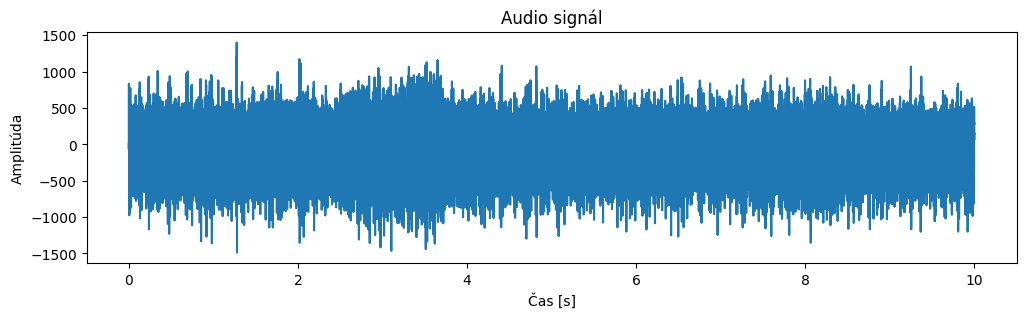

In [26]:
import numpy as np
from scipy.io import wavfile
import scipy.signal
import matplotlib.pyplot as plt



fs, x = wavfile.read('/content/drive/MyDrive/Colab Notebooks/xsugama00.wav')

t = np.arange(len(x)) / fs

plt.figure(figsize=(12, 3))
plt.plot(t, x)
plt.xlabel('Čas [s]')
plt.ylabel('Amplitúda')
plt.title('Audio signál')
plt.show()

16000 (160000,) int16 10.0


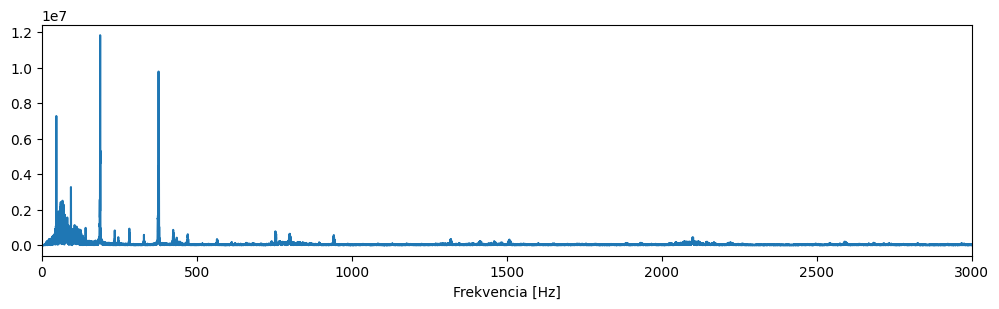

In [27]:
print(fs, x.shape, x.dtype, len(x) / fs)
x = x.astype(float)
X = np.abs(np.fft.rfft(x)) #DFT signál výpočet
f = np.fft.rfftfreq(len(x), 1/fs) #pole freq
plt.figure(figsize=(12, 3))
plt.plot(f, X)
plt.xlabel('Frekvencia [Hz]')
plt.xlim(0, 3000)
plt.show()

376.90000000000003
188.5
375.0


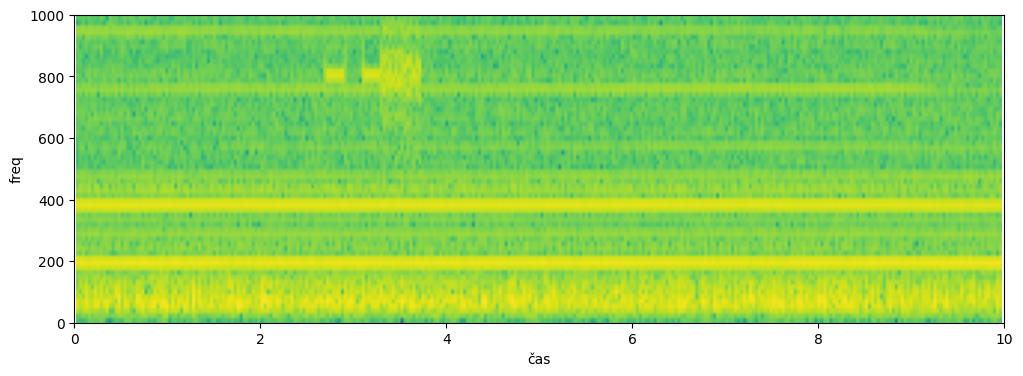

In [28]:
m = (f > 300) & (f < 450)
print(f[m][np.argmax(X[m])])
m = (f > 150) & (f < 200)
print(f[m][np.argmax(X[m])])
s1 = x[6400:9600]
f1 = np.fft.rfftfreq(len(s1), 1/fs)
print(f1[np.argmax(np.abs(np.fft.rfft(s1)))])

plt.figure(figsize=(12, 4))
plt.specgram(x, NFFT=1024, Fs=fs, noverlap=512)
plt.xlabel("čas")
plt.ylabel("freq")
plt.ylim(0, 1000)
plt.xlim(0, 10)
plt.show()


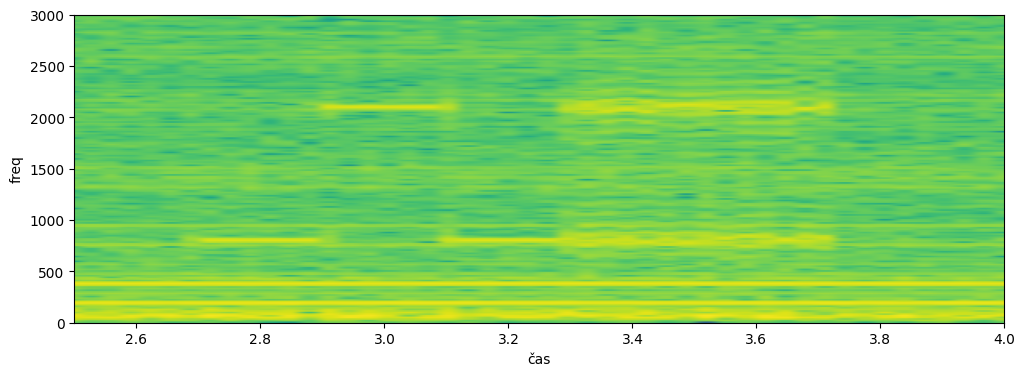

In [29]:
plt.figure(figsize=(12, 4))
plt.specgram(x, NFFT=1024, Fs=fs, noverlap=512)
plt.xlabel("čas")
plt.ylabel("freq")
plt.ylim(0, 3000); plt.xlim(2.5, 4.0); plt.show()

In [30]:
# Prvý úsek synchronizácie
s = x[int(2.72 * fs):int(2.88 * fs)]

fs_ = np.fft.rfftfreq(len(s), 1 / fs)
S = np.abs(np.fft.rfft(s))

m = (fs_ > 600) & (fs_ < 1000)
print("Prvý úsek, maximum v pásme [Hz]:", fs_[m][np.argmax(S[m])])


# Druhý úsek synchronizácie
s = x[int(2.92 * fs):int(3.08 * fs)]

fs_ = np.fft.rfftfreq(len(s), 1 / fs)
S = np.abs(np.fft.rfft(s))

m = (fs_ > 1900) & (fs_ < 2300)
print("Druhý úsek, maximum v pásme [Hz]:", fs_[m][np.argmax(S[m])])




Prvý úsek, maximum v pásme [Hz]: 800.0
Druhý úsek, maximum v pásme [Hz]: 2100.0


(2.5, 3.9)

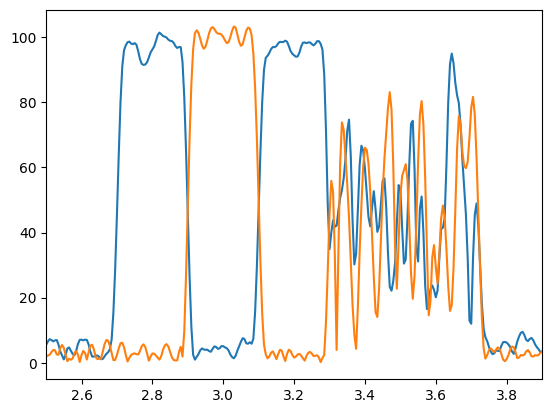

In [31]:

f_stft, t_stft, Z = scipy.signal.stft(x, fs=fs, nperseg=800, noverlap=720)
i800 = np.argmin(np.abs(f_stft - 800)) #do i800 vložíme index freq najbližšie k 800
i2100 = np.argmin(np.abs(f_stft - 2100))

plt.plot(t_stft, np.abs(Z[i800, :]), label='800 Hz')
plt.plot(t_stft, np.abs(Z[i2100, :]), label='2100 Hz')
plt.xlim(2.5, 3.9) #priblíženie


2.705


(2.5, 3.5)

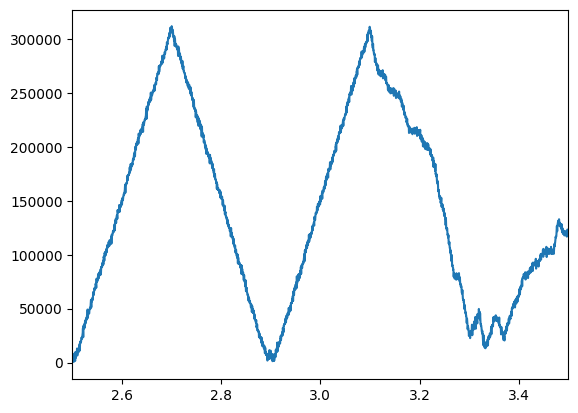

In [32]:
t0_odhad = t_stft[np.flatnonzero(np.abs(Z[i800, :]) > 50)[0]] #Uloží prvý čas keď veľkosť zložky pri 800 Hz prekročí zvolený prah 50
print(t0_odhad)

t_data_odhad = t0_odhad + 0.6
n0_odhad = round(t0_odhad * fs) #prevod časového odhadu na index vzorky
t_cast = np.arange(round(0.2 * fs)) / fs

vzor800_cos = np.cos(2 * np.pi * 800 * t_cast)
vzor800_sin = np.sin(2 * np.pi * 800 * t_cast)

k800_cos = scipy.signal.correlate(x, vzor800_cos, mode='valid')
k800_sin = scipy.signal.correlate(x, vzor800_sin, mode='valid')
k800 = np.sqrt(k800_cos**2 + k800_sin**2)


plt.plot(np.arange(len(k800)) / fs, k800)
plt.xlim(2.5, 3.5)

In [33]:
n0_korelacia = round(2.6 * fs) + np.argmax(k800[round(2.6 * fs):round(2.8 * fs)])
print(n0_korelacia, n0_korelacia / fs)

43203 2.7001875


In [34]:
n_data = n0_korelacia + round(0.6 * fs)

symbol1 = x[n_data:n_data + 160] #+160 kvôli 160 vzorkám čo je presne počet vzoriek za 10ms - dĺžka trvania signálu
t_symbol = np.arange(len(symbol1)) / fs
c800 = np.sum(symbol1 * np.exp(-2j * np.pi * 800 * t_symbol))
faza800 = np.angle(c800, deg=True)
c2100 = np.sum(symbol1 * np.exp(-2j * np.pi * 2100 * t_symbol))
faza2100 = np.angle(c2100, deg=True)
print(faza800, faza2100)


115.28052473930339 25.0285055780559


In [35]:
pocet_symbolov = (len(x) - n_data) // 160
symboly = x[n_data:n_data + pocet_symbolov * 160].reshape(pocet_symbolov, 160)

fazy800 = np.angle(np.sum(symboly * np.exp(-2j * np.pi * 800 * t_symbol), axis=1), deg=True)
fazy2100 = np.angle(np.sum(symboly * np.exp(-2j * np.pi * 2100 * t_symbol), axis=1), deg=True)
print(np.round(np.column_stack((fazy800, fazy2100)), 1))

[[ 115.3   25. ]
 [  52.8  -38.7]
 [ -69.9  138.5]
 ...
 [ -61.1  134.5]
 [ 177.4 -101.9]
 [  93.   151.7]]


In [36]:
zvysky800 = fazy800 % 60
zvysky2100 = fazy2100 % 60
print(np.round(np.column_stack((zvysky800, zvysky2100)), 1))

[[55.3 25. ]
 [52.8 21.3]
 [50.1 18.5]
 ...
 [58.9 14.5]
 [57.4 18.1]
 [33.  31.7]]


In [37]:
posun800 = np.angle(np.mean(np.exp(1j * np.deg2rad(6 * fazy800))), deg=True) / 6 #násobíme 6 kvôli tomu že 360/60 je 6
posun2100 = np.angle(np.mean(np.exp(1j * np.deg2rad(6 * fazy2100))), deg=True) / 6
print(posun800, posun2100)

-5.4771292248498 19.576640307559504


In [38]:
fazy800_zarovnane = (fazy800 - posun800) % 360
fazy2100_zarovnane = (fazy2100 - posun2100) % 360
print(np.round(np.column_stack((fazy800_zarovnane, fazy2100_zarovnane)), 1))

[[120.8   5.5]
 [ 58.2 301.7]
 [295.5 118.9]
 ...
 [304.4 115. ]
 [182.9 238.5]
 [ 98.5 132.1]]


In [39]:
idx800 = np.round(fazy800_zarovnane / 60) % 6
idx2100 = np.round(fazy2100_zarovnane / 60) % 6
print(np.column_stack((idx800, idx2100)))

[[2. 0.]
 [1. 5.]
 [5. 2.]
 ...
 [5. 2.]
 [3. 4.]
 [2. 2.]]


In [40]:
N = round(0.2 * fs)
t_sync = np.arange(N) / fs

for k in range(3):
    zac = n0_korelacia + k * N
    usek = x[zac:zac + N]
    c800 = np.sum(usek * np.exp(-2j * np.pi * 800 * t_sync))
    c2100 = np.sum(usek * np.exp(-2j * np.pi * 2100 * t_sync))
    print(k + 1, round(np.angle(c800, deg=True), 2), round(np.angle(c2100, deg=True), 2))

1 -35.91 -77.64
2 148.16 51.6
3 -35.99 131.56


In [41]:
fazy800_cal = (fazy800 - (-35.95 + 90)) % 360 #číslo je referenčná konštanta zo synchornizácie
fazy2100_cal = (fazy2100 - (51.60 + 90)) % 360

idx800 = np.round(fazy800_cal / 60).astype(int) % 6
idx2100 = np.round(fazy2100_cal / 60).astype(int) % 6

dvojice = np.column_stack((idx800, idx2100))
print(len(dvojice))
print(dvojice[-20:])

669
[[4 4]
 [4 3]
 [1 0]
 [1 5]
 [0 3]
 [3 0]
 [1 1]
 [4 1]
 [4 3]
 [3 1]
 [2 0]
 [0 5]
 [0 2]
 [1 4]
 [1 3]
 [0 5]
 [2 3]
 [4 0]
 [2 2]
 [1 0]]


In [42]:
sila = np.sqrt(np.mean(symboly.astype(float) ** 2, axis=1))
print(np.column_stack((dvojice[-20:], np.round(sila[-20:], 1))))

[[  4.    4.  376.6]
 [  4.    3.  514.2]
 [  1.    0.  336.9]
 [  1.    5.  368.2]
 [  0.    3.  313.6]
 [  3.    0.  325.9]
 [  1.    1.  306.6]
 [  4.    1.  295.2]
 [  4.    3.  287.4]
 [  3.    1.  296.1]
 [  2.    0.  341.6]
 [  0.    5.  349.5]
 [  0.    2.  327.7]
 [  1.    4.  487.7]
 [  1.    3.  324.8]
 [  0.    5.  356.1]
 [  2.    3.  366.7]
 [  4.    0.  298.4]
 [  2.    2.  308.1]
 [  1.    0.  372.6]]


In [43]:
a800 = 2 * np.abs(np.sum(symboly * np.exp(-2j * np.pi * 800 * t_symbol), axis=1)) / 160
a2100 = 2 * np.abs(np.sum(symboly * np.exp(-2j * np.pi * 2100 * t_symbol), axis=1)) / 160

print("Prvych 5:")
print(np.round(np.column_stack((a800[:5], a2100[:5])), 1))
print("Poslednych 20:")
print(np.round(np.column_stack((a800[-20:], a2100[-20:])), 1))

Prvych 5:
[[185.7 218.4]
 [208.7 206.8]
 [229.  201.3]
 [225.8 208.1]
 [222.7 189.2]]
Poslednych 20:
[[44.3 11.1]
 [38.9 23.2]
 [15.8  6.8]
 [51.9 30.9]
 [13.1  2.3]
 [26.5 11. ]
 [14.7 10.8]
 [26.  17.3]
 [27.6  8.6]
 [34.4 12.8]
 [22.2 15.1]
 [24.7 17.8]
 [ 5.4 15.6]
 [23.3 12.5]
 [13.6 12.7]
 [10.1  4. ]
 [ 6.  22. ]
 [18.5 15.7]
 [21.1  1.6]
 [51.9 20.9]]


In [44]:
silne = np.flatnonzero((a800 > 100) & (a2100 > 100))
print("Posledne silne intervaly:", silne[-10:])
print("Ich dvojice:")
print(dvojice[silne[-10:]])

Posledne silne intervaly: [32 33 34 35 36 37 38 39 40 41]
Ich dvojice:
[[2 0]
 [1 2]
 [1 5]
 [1 2]
 [2 2]
 [2 1]
 [0 0]
 [2 5]
 [4 4]
 [5 5]]


In [45]:
koniec = silne[-1]
data = dvojice[:koniec]

print("Pocet znakov:", len(data))
print(data)

Pocet znakov: 41
[[1 4]
 [0 3]
 [4 0]
 [0 1]
 [4 0]
 [4 2]
 [3 0]
 [0 4]
 [4 2]
 [4 1]
 [0 0]
 [4 2]
 [3 0]
 [2 3]
 [0 0]
 [2 1]
 [1 2]
 [4 2]
 [2 3]
 [1 5]
 [0 0]
 [3 1]
 [1 2]
 [1 5]
 [2 2]
 [4 3]
 [4 2]
 [1 3]
 [3 0]
 [0 4]
 [2 0]
 [4 2]
 [2 0]
 [1 2]
 [1 5]
 [1 2]
 [2 2]
 [2 1]
 [0 0]
 [2 5]
 [4 4]]


In [46]:
hodnoty1 = 6 * data[:, 0] + data[:, 1]
hodnoty2 = 6 * data[:, 1] + data[:, 0]

print("800 Hz ako vyssia cifra:", hodnoty1)
print("2100 Hz ako vyssia cifra:", hodnoty2)

800 Hz ako vyssia cifra: [10  3 24  1 24 26 18  4 26 25  0 26 18 15  0 13  8 26 15 11  0 19  8 11
 14 27 26  9 18  4 12 26 12  8 11  8 14 13  0 17 28]
2100 Hz ako vyssia cifra: [25 18  4  6  4 16  3 24 16 10  0 16  3 20  0  8 13 16 20 31  0  9 13 31
 14 22 16 19  3 24  2 16  2 13 31 13 14  8  0 32 28]


In [47]:
abeceda = "ABCDEFGHIJKLMNOPQRSTUVWXYZ ,."
zprava = "".join(abeceda[h] for h in hodnoty1)
print(zprava)

KDYBY SE ZA SPANI PLATILO, JSEM MILIONAR.


In [48]:
with open("zprava.txt", "w", encoding="utf-8") as f:
    f.write(zprava)